# Cell 1: Auto-Detect Paths & Calibrate PCU Thresholds

In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 kB 3.5 MB/s eta 0:00:00


# Clear Working Directory

In [2]:
!rm -rf /kaggle/working/*

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Hunting for mounted datasets and model weights...
Success! Found model at: /kaggle/input/datasets/sharminaktermukta/yolov8-best-pt/best.pt
Success! Found Validation folder at: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/val/images
Calculating traffic density across the validation set...


100%|██████████| 1000/1000 [02:41<00:00,  6.19it/s]



--- Dynamic Congestion Thresholds ---
Low Congestion   : 0.0 to 7.93 PCU
Medium Congestion: 7.93 to 15.10 PCU
High Congestion  : > 15.10 PCU


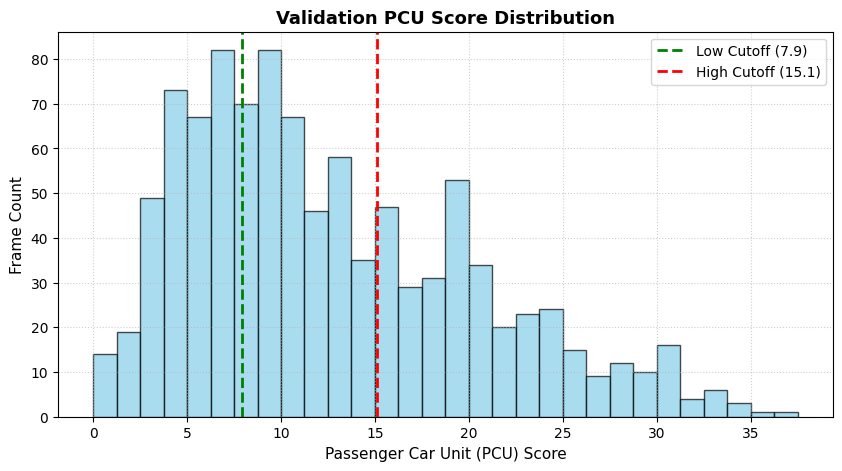

In [3]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import requests
from ultralytics import YOLO
from tqdm import tqdm

print("Hunting for mounted datasets and model weights...")

# 1. Auto-Detect the Model Weights (best.pt)
MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find 'best.pt'. Make sure it is added via 'Add Input'.")
print(f"Success! Found model at: {MODEL_PATH}")

# 2. Auto-Detect the Validation Images Directory
VAL_IMAGES_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'tfp_dataset' in dirs:
        VAL_IMAGES_DIR = os.path.join(root, 'tfp_dataset', 'val', 'images')
        break

if not VAL_IMAGES_DIR or not os.path.exists(VAL_IMAGES_DIR):
    raise FileNotFoundError("Could not find the 'val/images' folder. Check your mounted inputs.")
print(f"Success! Found Validation folder at: {VAL_IMAGES_DIR}")

# 3. Load Model and Fetch Images
model = YOLO(MODEL_PATH)
val_images = [os.path.join(VAL_IMAGES_DIR, f) for f in os.listdir(VAL_IMAGES_DIR) if f.endswith(('.jpg', '.png', '.jpeg'))]

# 4. PCU Weights Dictionary for the 9 Target Classes (Global Variable)
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}

# 5. Compute PCU Score Distribution
pcu_scores = []
print("Calculating traffic density across the validation set...")

for img_path in tqdm(val_images[:1000]):  
    results = model.predict(source=img_path, conf=0.35, verbose=False)[0]
    frame_pcu = 0.0
    for box in results.boxes:
        cls_name = results.names[int(box.cls[0].item())]
        frame_pcu += PCU_WEIGHTS.get(cls_name, 0.5)
    pcu_scores.append(frame_pcu)

pcu_scores = np.array(pcu_scores)

# 6. Extract Statistical Percentile Cutoffs (Tertiles)
low_cutoff = np.percentile(pcu_scores, 33.3)
high_cutoff = np.percentile(pcu_scores, 66.6)

print(f"\n--- Dynamic Congestion Thresholds ---")
print(f"Low Congestion   : 0.0 to {low_cutoff:.2f} PCU")
print(f"Medium Congestion: {low_cutoff:.2f} to {high_cutoff:.2f} PCU")
print(f"High Congestion  : > {high_cutoff:.2f} PCU")

# 7. Generate Distribution Visual
plt.figure(figsize=(10, 5))
plt.hist(pcu_scores, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(low_cutoff, color='green', linestyle='--', linewidth=2, label=f'Low Cutoff ({low_cutoff:.1f})')
plt.axvline(high_cutoff, color='red', linestyle='--', linewidth=2, label=f'High Cutoff ({high_cutoff:.1f})')
plt.title('Validation PCU Score Distribution', fontsize=13, fontweight='bold')
plt.xlabel('Passenger Car Unit (PCU) Score', fontsize=11)
plt.ylabel('Frame Count', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [4]:
!pip install sahi -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.6/156.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.6 MB/s eta 0:00:00


# Cell 2: Supercharged Internet Inference (Test Time Augmentation)

Hunting for model weights...
Scout detected 3 objects. Routing to Standard Inference...
Success! Annotated image saved to: /kaggle/working/dynamic_test_ANALYZED4.jpg


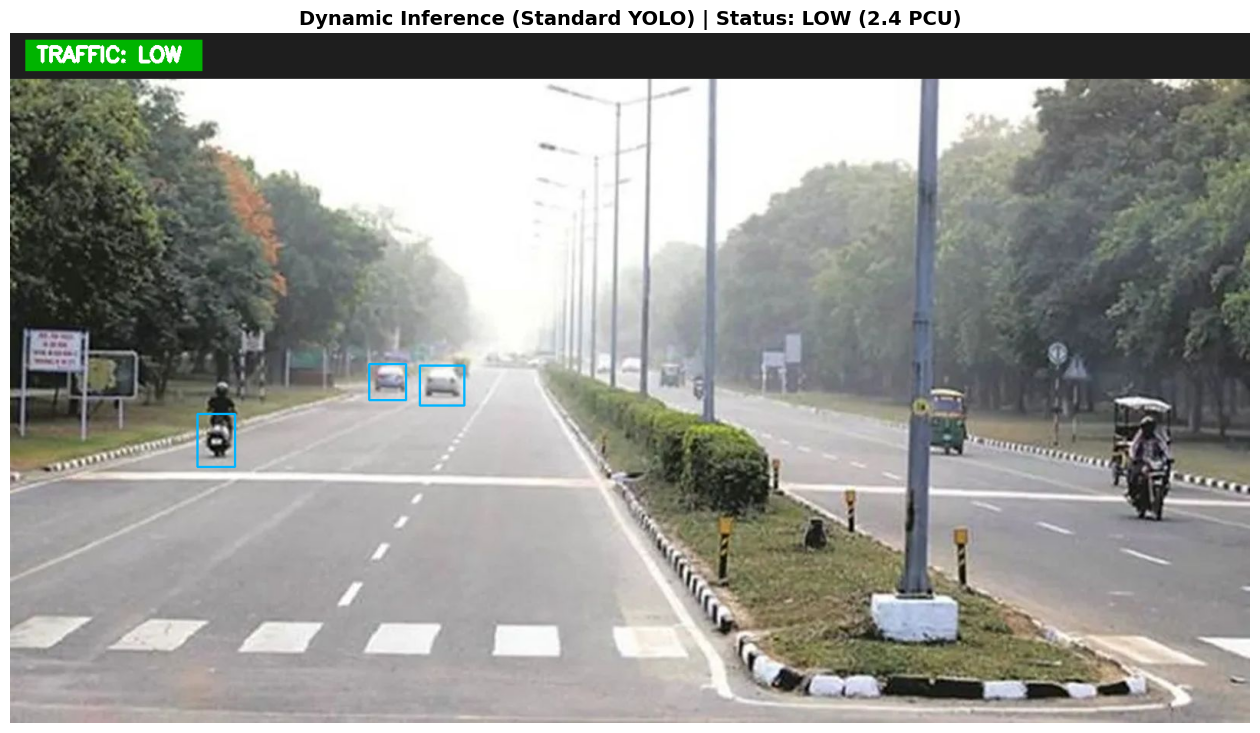

In [5]:
import os
import cv2
import requests
import numpy as np
import matplotlib.pyplot as plt
import torch
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction

print("Hunting for model weights...")

MODEL_PATH = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if not MODEL_PATH:
    raise FileNotFoundError("Could not find 'best.pt'. Make sure it is added via 'Add Input'.")

# PCU Weights and Thresholds mapped to your dataset
PCU_WEIGHTS = {
    'Car': 1.0, 'Bus': 3.0, 'Truck': 3.0, 'Mini-Truck': 1.5,
    'CNG': 0.75, 'Rickshaw': 0.8, 'Motorcycle': 0.4, 'Bicycle': 0.3, 'Pedestrian': 0.0
}
low_cutoff, high_cutoff = 8.45, 15.80

# Load both standard and SAHI models into memory
standard_model = YOLO(MODEL_PATH)
device_type = "cuda:0" if torch.cuda.is_available() else "cpu"
sahi_model = AutoDetectionModel.from_pretrained(
    model_type='yolov8', model_path=MODEL_PATH, confidence_threshold=0.18, device=device_type
)

def smart_traffic_analyzer(image_path):
    img = cv2.imread(image_path)
    h, w, _ = img.shape
    
    # 1. THE SCOUT PASS
    scout_results = standard_model.predict(source=image_path, conf=0.25, imgsz=1024, verbose=False)[0]
    num_scout_objects = len(scout_results.boxes)
    
    boxes_data = []
    
    # 2. AUTO-ROUTING LOGIC
    if num_scout_objects > 35:
        print(f"Scout detected {num_scout_objects} objects. Routing to SAHI Deep-Scan...")
        mode = "SAHI Macro-Zoom"
        
        result = get_sliced_prediction(
            image_path, sahi_model,
            slice_height=256, slice_width=256,
            overlap_height_ratio=0.4, overlap_width_ratio=0.4,
            postprocess_type="NMS", postprocess_match_threshold=0.4 
        )
        
        for obj in result.object_prediction_list:
            cls_name = obj.category.name
            if cls_name in PCU_WEIGHTS:
                bbox = obj.bbox
                boxes_data.append({'name': cls_name, 'xyxy': [int(bbox.minx), int(bbox.miny), int(bbox.maxx), int(bbox.maxy)]})
    else:
        print(f"Scout detected {num_scout_objects} objects. Routing to Standard Inference...")
        mode = "Standard YOLO"
        
        for box in scout_results.boxes:
            cls_name = scout_results.names[int(box.cls[0].item())]
            if cls_name in PCU_WEIGHTS:
                x1, y1, x2, y2 = map(int, box.xyxy[0])
                boxes_data.append({'name': cls_name, 'xyxy': [x1, y1, x2, y2]})

    # 3. PCU CALCULATION (This was the missing block!)
    total_pcu = 0.0
    for b in boxes_data:
        total_pcu += PCU_WEIGHTS.get(b['name'], 0.0)
        x1, y1, x2, y2 = b['xyxy']
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 180, 0), 2)

    # 4. Status Evaluation
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)      
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)    
    else:
        status, banner_color = "HIGH", (0, 0, 220)      

    # 5. Overlay Minimalist HUD Banner
    cv2.rectangle(img, (0, 0), (w, 60), (30, 30, 30), -1)
    cv2.rectangle(img, (20, 10), (250, 50), banner_color, -1)
    cv2.putText(img, f"TRAFFIC: {status}", (35, 38), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 3)

    return img, status, total_pcu, mode

# --- EXECUTION ---
IMAGE_URL = "https://cf-img-a-in.tosshub.com/sites/visualstory/wp/2024/05/Chandigarh.webp?size=*:900"
download_path = "/kaggle/working/dynamic_test_RAW4.jpg"
output_path = "/kaggle/working/dynamic_test_ANALYZED4.jpg" 

print("Downloading image...")
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(IMAGE_URL, headers=headers)
with open(download_path, 'wb') as f:
    f.write(response.content)

rendered_frame, level, score, active_mode = smart_traffic_analyzer(download_path)

cv2.imwrite(output_path, rendered_frame)
print(f"Success! Annotated image saved to: {output_path}")

plt.figure(figsize=(16, 10))
plt.imshow(cv2.cvtColor(rendered_frame, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f"Dynamic Inference ({active_mode}) | Status: {level} ({score:.1f} PCU)", fontsize=14, fontweight='bold')
plt.show()

# Cell 3: Real-Time Video Tracker

In [6]:
# 1. Locate the Uploaded Test Video Dynamically
INPUT_VIDEO = None
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        if file.endswith('.mp4'):
            INPUT_VIDEO = os.path.join(root, file)
            break
    if INPUT_VIDEO: break

if not INPUT_VIDEO:
    raise FileNotFoundError("Could not find an .mp4 file. Please upload a test video via 'Add Input'.")

OUTPUT_VIDEO = '/kaggle/working/traffic_analyzed.mp4'

# 2. Video Capture & Writer Setup
cap = cv2.VideoCapture(INPUT_VIDEO)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = int(cap.get(cv2.CAP_PROP_FPS))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(OUTPUT_VIDEO, fourcc, fps, (width, height))

print(f"Processing Video: {INPUT_VIDEO} ({total_frames} frames)")

# 3. Frame-by-Frame Processing Loop
frame_count = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
        
    frame_count += 1
    if frame_count % 30 == 0:
        print(f"Processing frame {frame_count}/{total_frames}...")

    # Standard inference for video (TTA is too slow for thousands of frames)
    results = model.predict(source=frame, conf=0.35, verbose=False)[0]
    total_pcu = 0.0
    
    # Draw detections
    for box in results.boxes:
        cls_id = int(box.cls[0].item())
        cls_name = results.names[cls_id]
        
        total_pcu += PCU_WEIGHTS.get(cls_name, 0.0)
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        
        cv2.rectangle(frame, (x1, y1), (x2, y2), (255, 180, 0), 2)
        cv2.putText(frame, f"{cls_name}", (x1, max(20, y1 - 5)), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)

    # Calculate status banner colors using the thresholds from Cell 1
    if total_pcu < low_cutoff:
        status, banner_color = "LOW", (0, 180, 0)
    elif total_pcu <= high_cutoff:
        status, banner_color = "MEDIUM", (0, 165, 255)
    else:
        status, banner_color = "HIGH", (0, 0, 220)

    # Render HUD Overlay
    cv2.rectangle(frame, (0, 0), (width, 60), (30, 30, 30), -1)
    cv2.rectangle(frame, (20, 12), (180, 48), banner_color, -1)
    
    cv2.putText(frame, f"TRAFFIC: {status}", (30, 37), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
    cv2.putText(frame, f"Total PCU: {total_pcu:.2f} | Objects: {len(results.boxes)}", 
                (200, 37), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (220, 220, 220), 2)

    out.write(frame)

cap.release()
out.release()
print(f"\nSuccess! Analyzed video saved to: {OUTPUT_VIDEO}")

Processing Video: /kaggle/input/datasets/sharminaktermukta/demo-video/188613-883402208_medium.mp4 (660 frames)
Processing frame 30/660...
Processing frame 60/660...
Processing frame 90/660...
Processing frame 120/660...
Processing frame 150/660...
Processing frame 180/660...
Processing frame 210/660...
Processing frame 240/660...
Processing frame 270/660...
Processing frame 300/660...
Processing frame 330/660...
Processing frame 360/660...
Processing frame 390/660...
Processing frame 420/660...
Processing frame 450/660...
Processing frame 480/660...
Processing frame 510/660...
Processing frame 540/660...
Processing frame 570/660...
Processing frame 600/660...
Processing frame 630/660...
Processing frame 660/660...

Success! Analyzed video saved to: /kaggle/working/traffic_analyzed.mp4


In [7]:
!pip install -q ultralytics==8.4.152

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.6 MB/s eta 0:00:00


In [8]:
import ultralytics
print("Ultralytics version:", ultralytics.__version__)

from ultralytics import YOLO

print("YOLO imported successfully!")

Ultralytics version: 8.4.202
YOLO imported successfully!


In [9]:
import os
import pandas as pd
from tqdm import tqdm
from ultralytics import YOLO
import numpy as np

# ==================================
# 1. FIND MODEL
# ==================================

MODEL_PATH = None

for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if MODEL_PATH is None:
    raise FileNotFoundError("best.pt not found!")

print("Model:", MODEL_PATH)

# ==================================
# 2. FIND VALIDATION IMAGES
# ==================================

VAL_IMAGES_DIR = None

for root, dirs, files in os.walk('/kaggle/input'):
    if 'tfp_dataset' in dirs:
        candidate = os.path.join(
            root, 'tfp_dataset', 'val', 'images'
        )

        if os.path.isdir(candidate):
            VAL_IMAGES_DIR = candidate
            break

if VAL_IMAGES_DIR is None:
    raise FileNotFoundError("Validation images not found!")

val_images = [
    os.path.join(VAL_IMAGES_DIR, f)
    for f in os.listdir(VAL_IMAGES_DIR)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
]

print("Validation images:", len(val_images))

# ==================================
# 3. PCU SETTINGS
# ==================================

PCU_WEIGHTS = {
    'Car': 1.0,
    'Bus': 3.0,
    'Truck': 3.0,
    'Mini-Truck': 1.5,
    'CNG': 0.75,
    'Rickshaw': 0.8,
    'Motorcycle': 0.4,
    'Bicycle': 0.3,
    'Pedestrian': 0.0
}

low_cutoff = 8.45
high_cutoff = 15.80

# ==================================
# 4. LOAD EXISTING MODEL
# ==================================

model = YOLO(MODEL_PATH)

# ==================================
# 5. PREDICTION AND CSV
# ==================================

rows = []

OUTPUT_DIR = "/kaggle/working/yolov8_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for img_path in tqdm(val_images):

    result = model.predict(
        source=img_path,
        conf=0.35,
        verbose=False
    )[0]

    class_counts = {k: 0 for k in PCU_WEIGHTS}
    total_pcu = 0.0
    confidences = []

    for box in result.boxes:

        cls_id = int(box.cls[0].item())
        cls_name = result.names[cls_id]

        if cls_name not in PCU_WEIGHTS:
            continue

        conf = float(box.conf[0].item())

        class_counts[cls_name] += 1
        total_pcu += PCU_WEIGHTS[cls_name]
        confidences.append(conf)

    if total_pcu < low_cutoff:
        congestion = "Low"
    elif total_pcu <= high_cutoff:
        congestion = "Medium"
    else:
        congestion = "High"

    rows.append({
        "image_name": os.path.basename(img_path),
        **{f"{k}_count": v for k, v in class_counts.items()},
        "total_vehicles": sum(class_counts.values()),
        "mean_confidence": np.mean(confidences) if confidences else 0,
        "total_pcu": total_pcu,
        "congestion_level": congestion
    })

# ==================================
# 6. SAVE CSV
# ==================================

df = pd.DataFrame(rows)

csv_path = os.path.join(
    OUTPUT_DIR,
    "yolov8_validation_pcu_results.csv"
)

df.to_csv(csv_path, index=False)

print("\nCSV CREATED SUCCESSFULLY!")
print("Location:", csv_path)
print("Total Images:", len(df))

display(df.head(10))

print("\nCongestion Distribution:")
print(df['congestion_level'].value_counts())

# Download CSV
from IPython.display import FileLink, display

display(FileLink(csv_path))

Model: /kaggle/input/datasets/sharminaktermukta/yolov8-best-pt/best.pt
Validation images: 4736


100%|██████████| 4736/4736 [08:47<00:00,  8.98it/s]


CSV CREATED SUCCESSFULLY!
Location: /kaggle/working/yolov8_results/yolov8_validation_pcu_results.csv
Total Images: 4736


,image_name,Car_count,Bus_count,Truck_count,Mini-Truck_count,CNG_count,Rickshaw_count,Motorcycle_count,Bicycle_count,Pedestrian_count,total_vehicles,mean_confidence,total_pcu,congestion_level
0,frame0_jpg.rf.04aae619e988bec5c305be2c6d48b701...,7,0,0,0,2,2,0,0,0,11,0.652629,10.10,Medium
1,frame0_jpg.rf.1b8289b722c9f3995224b17475e83039...,5,6,0,2,0,4,0,0,0,17,0.655725,29.20,High
2,frame0_jpg.rf.24567b852d98da0a54436f6968779088...,5,5,0,1,1,4,1,0,2,19,0.676559,25.85,High
3,frame0_jpg.rf.4414dca39a1e1b2a186d9ea94500f025...,0,2,0,0,2,0,0,0,0,4,0.565950,7.50,Low
4,frame0_jpg.rf.59bc026da8d18d8d50a2ddf1a25aeeaa...,4,1,0,0,0,0,0,0,0,5,0.561280,7.00,Low
5,frame0_jpg.rf.8092ceebe33c1222541b5b553b800d37...,3,3,0,0,3,6,0,0,2,17,0.739978,19.05,High
6,frame0_jpg.rf.9fcb7af2694e1cd7e1ced9fc78009b35...,1,1,0,0,1,2,0,0,0,5,0.593046,6.35,Low
7,frame0_jpg.rf.bf547b888a1620e749eb9ba066f40e6f...,0,2,0,0,0,0,0,0,1,3,0.532278,6.00,Low
8,frame0_jpg.rf.e1bc04102d10d13d3e4801450a664640...,4,0,0,1,0,2,0,0,0,7,0.530045,7.10,Low
9,frame0_jpg.rf.e31b2daf1786ff18e7124ea1c12b66dc...,3,5,0,0,1,7,0,0,6,22,0.669143,24.35,High



Congestion Distribution:
congestion_level
Medium    1695
High      1537
Low       1504
Name: count, dtype: int64


/kaggle/working/yolov8_results/yolov8_validation_pcu_results.csv

In [10]:
import os

BASE = "/kaggle/input"

for root, dirs, files in os.walk(BASE):
    if "images" in dirs or "labels" in dirs:
        print("Folder:", root)
        print("Subfolders:", dirs)
        print("----------------------")

Folder: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test
Subfolders: ['images', 'labels']
----------------------
Folder: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/train
Subfolders: ['images', 'labels']
----------------------
Folder: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/val
Subfolders: ['images', 'labels']
----------------------


In [11]:
!pip install ultralytics

In [12]:
from ultralytics import YOLO
import os

# Automatically find best.pt
MODEL_PATH = None

for root, dirs, files in os.walk('/kaggle/input'):
    if 'best.pt' in files:
        MODEL_PATH = os.path.join(root, 'best.pt')
        break

if MODEL_PATH is None:
    raise FileNotFoundError("best.pt not found!")

# Load YOLOv8 model
model = YOLO(MODEL_PATH)

print("YOLOv8 model loaded successfully!")
print("Class names:", model.names)

YOLOv8 model loaded successfully!
Class names: {0: 'Car', 1: 'Bus', 2: 'Truck', 3: 'Motorcycle', 4: 'Bicycle', 5: 'Rickshaw', 6: 'Mini-Truck', 7: 'CNG', 8: 'Pedestrian'}


Test Images: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/images
Test Labels: /kaggle/input/notebooks/sharminaktermukta/data-preparation/tfp_dataset/test/labels
Total test images: 2368

Test evaluation completed!


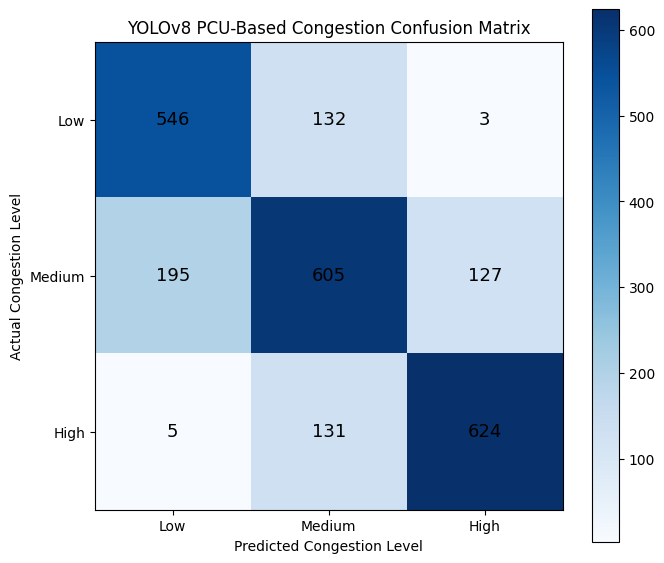


Classification Report:


,precision,recall,f1-score,support
Low,0.7319,0.8018,0.7652,681.0000
Medium,0.6970,0.6526,0.6741,927.0000
High,0.8276,0.8211,0.8243,760.0000
accuracy,0.7496,0.7496,0.7496,0.7496
macro avg,0.7522,0.7585,0.7545,2368.0000
weighted avg,0.7490,0.7496,0.7485,2368.0000



Overall Congestion Accuracy: 74.96%

All files saved in /kaggle/working/


In [13]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# ==========================================
# 1. FIND TEST IMAGES AND GROUND-TRUTH LABELS
# ==========================================

TEST_IMAGES_DIR = None

for root, dirs, files in os.walk('/kaggle/input'):
    if os.path.basename(root) == 'images' and os.path.basename(os.path.dirname(root)) == 'test':
        TEST_IMAGES_DIR = root
        break

if TEST_IMAGES_DIR is None:
    raise FileNotFoundError("Test images folder not found!")

TEST_LABELS_DIR = os.path.join(
    os.path.dirname(TEST_IMAGES_DIR),
    'labels'
)

if not os.path.exists(TEST_LABELS_DIR):
    raise FileNotFoundError("Test labels folder not found!")

print("Test Images:", TEST_IMAGES_DIR)
print("Test Labels:", TEST_LABELS_DIR)

# ==========================================
# 2. PCU WEIGHTS AND CONGESTION THRESHOLDS
# ==========================================

PCU_WEIGHTS = {
    'Car': 1.0,
    'Bus': 3.0,
    'Truck': 3.0,
    'Mini-Truck': 1.5,
    'CNG': 0.75,
    'Rickshaw': 0.8,
    'Motorcycle': 0.4,
    'Bicycle': 0.3,
    'Pedestrian': 0.0
}

# Use the thresholds calibrated in Cell 1
low_cutoff = 8.45
high_cutoff = 15.80

CLASS_LABELS = ['Low', 'Medium', 'High']

# ==========================================
# 3. CONVERT PCU INTO CONGESTION LEVEL
# ==========================================

def get_congestion_level(pcu):
    if pcu < low_cutoff:
        return 'Low'
    elif pcu <= high_cutoff:
        return 'Medium'
    else:
        return 'High'

# ==========================================
# 4. GET GROUND-TRUTH PCU FROM YOLO LABELS
# ==========================================

def calculate_gt_pcu(label_path):
    total_pcu = 0.0

    if not os.path.exists(label_path):
        raise FileNotFoundError(
            f"Missing annotation file: {label_path}"
        )

    with open(label_path, 'r') as f:
        for line in f:
            values = line.strip().split()

            if not values:
                continue

            class_id = int(float(values[0]))

            # Convert class ID into class name
            class_name = model.names[class_id]

            total_pcu += PCU_WEIGHTS.get(class_name, 0.0)

    return total_pcu

# ==========================================
# 5. PREDICT PCU AND COMPARE WITH GROUND TRUTH
# ==========================================

image_extensions = ('.jpg', '.jpeg', '.png')

test_images = sorted([
    os.path.join(TEST_IMAGES_DIR, f)
    for f in os.listdir(TEST_IMAGES_DIR)
    if f.lower().endswith(image_extensions)
])

y_true = []
y_pred = []

results_data = []

print(f"Total test images: {len(test_images)}")

for image_path in test_images:

    image_name = os.path.basename(image_path)
    label_name = os.path.splitext(image_name)[0] + '.txt'
    label_path = os.path.join(TEST_LABELS_DIR, label_name)

    # Ground-truth PCU from annotations
    gt_pcu = calculate_gt_pcu(label_path)

    # Predicted PCU from YOLOv8 detections
    prediction = model.predict(
        source=image_path,
        conf=0.35,
        verbose=False
    )[0]

    predicted_pcu = 0.0

    for box in prediction.boxes:
        class_id = int(box.cls[0].item())
        class_name = prediction.names[class_id]

        predicted_pcu += PCU_WEIGHTS.get(class_name, 0.0)

    # Convert PCU into congestion classes
    actual_level = get_congestion_level(gt_pcu)
    predicted_level = get_congestion_level(predicted_pcu)

    y_true.append(actual_level)
    y_pred.append(predicted_level)

    results_data.append({
        'Image': image_name,
        'Ground_Truth_PCU': round(gt_pcu, 2),
        'Predicted_PCU': round(predicted_pcu, 2),
        'Actual_Level': actual_level,
        'Predicted_Level': predicted_level
    })

print("\nTest evaluation completed!")

# ==========================================
# 6. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=CLASS_LABELS
)

plt.figure(figsize=(7, 6))

plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('YOLOv8 PCU-Based Congestion Confusion Matrix')
plt.colorbar()

tick_marks = np.arange(len(CLASS_LABELS))

plt.xticks(tick_marks, CLASS_LABELS)
plt.yticks(tick_marks, CLASS_LABELS)

plt.xlabel('Predicted Congestion Level')
plt.ylabel('Actual Congestion Level')

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha='center',
            va='center',
            color='black',
            fontsize=13
        )

plt.tight_layout()
plt.savefig(
    '/kaggle/working/yolov8_congestion_confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

# ==========================================
# 7. PRECISION, RECALL, F1-SCORE, SUPPORT
# ==========================================

report = classification_report(
    y_true,
    y_pred,
    labels=CLASS_LABELS,
    target_names=CLASS_LABELS,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("\nClassification Report:")
display(report_df.round(4))

accuracy = accuracy_score(y_true, y_pred)

print(f"\nOverall Congestion Accuracy: {accuracy * 100:.2f}%")

# ==========================================
# 8. SAVE RESULTS
# ==========================================

report_df.to_csv(
    '/kaggle/working/yolov8_congestion_classification_report.csv'
)

pd.DataFrame(
    cm,
    index=[f'Actual_{x}' for x in CLASS_LABELS],
    columns=[f'Predicted_{x}' for x in CLASS_LABELS]
).to_csv('/kaggle/working/yolov8_congestion_confusion_matrix.csv')

pd.DataFrame(results_data).to_csv(
    '/kaggle/working/yolov8_congestion_test_predictions.csv',
    index=False
)

print("\nAll files saved in /kaggle/working/")
